In [1]:
import os

# For headless MuJoCo rendering on a remote GPU server
os.environ["MUJOCO_GL"] = "egl"

from dataclasses import dataclass, asdict
import numpy as np
import torch
import gymnasium as gym
import torch.nn as nn
from torch.distributions import Normal
from collections import deque
import torch.nn.functional as F
import matplotlib.pyplot as plt
import imageio.v2 as imageio
from pathlib import Path
from IPython.display import Video, display
import pandas as pd
from pathlib import Path
import json
import mujoco


@dataclass
class LDRConfig:
    # SAC and training settings (Xu: configs/agents/hopper/ldr.yaml)
    total_timesteps: int = 1_500_000
    learning_starts: int = 0             # Xu: train_start_iterations = 0, policy acts from the start
    train_freq: int = 2048               # env steps collected per optimize() call
    gradient_steps: int = 2048           # gradient updates per optimize() call (1 per env step)
    batch_size: int = 256
    eval_interval: int = 100_000
    buffer_size: int = 1_000_000
    gamma: float = 0.99
    tau: float = 0.005
    learning_rate: float = 3e-4
    reward_scale: float = 0.008
    target_update_interval: int = 1
    hidden_dim: int = 256
    seed: int = 1012

    # LDR-specific settings
    n_past: int = 50
    latent_dim: int = 3                  # Xu uses 5 only for Ant
    vae_loss_weight: float = 5.0
    contrastive_loss_weight: float = 1.0
    infonce_temp: float = 1.0
    contrastive_start_iterations: int = 0
    latent_dropout_prob: float = 0.1
    min_positives: int = 1

    # KL annealing (Xu's kl_schedule): beta goes 0 -> beta_max linearly
    # over the first beta_anneal_fraction of training, then stays at beta_max
    beta_max: float = 0.1
    beta_anneal_fraction: float = 0.5

In [9]:
class HistoryQueue:
    def __init__(self, n_envs, n_past, obs_dim, action_dim):
        self.n_envs, self.H, self.obs_dim, self.action_dim = n_envs, n_past, obs_dim, action_dim
        self.data = np.zeros((n_envs, n_past, obs_dim + action_dim), dtype=np.float32)
    
    def get(self):
        return self.data.copy()
    
    def append(self, obs, actions):
        # shifting all data except the last 1 row. then add the new obs and actions to the first row
        self.data[:,1:] = self.data[:,:-1].copy()
        self.data[:,0,:self.obs_dim] = obs
        self.data[:,0,self.obs_dim:] = actions
    
    # def reset_done(self, dones):
    #     self.data[np.asarray(dones, dtype=bool)] = 0

    def reset_done(self, dones, initial_obs=None):
        dones = np.asarray(dones, dtype=bool)
        self.data[dones] = 0
        if initial_obs is not None:
            self.data[dones, :, :self.obs_dim] = initial_obs[dones][:, None, :]


In [3]:
# Need to send latent_dim from the LDRAgent

class Actor(nn.Module):

    def __init__(self, obs_dim, action_dim, hidden_dim=256, latent_dim=0):
        super().__init__()
        self.latent_dim = latent_dim
        if latent_dim > 0:
            self.latent_norm = nn.LayerNorm(latent_dim)

        # Shared feature extractor
        self.net = nn.Sequential(
            nn.Linear(obs_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU()
        )

        # Gaussian distribution parameters
        self.mu = nn.Linear(hidden_dim, action_dim)
        self.log_std = nn.Linear(hidden_dim, action_dim)
        self.log_std_min = -20
        self.log_std_max = 2

    def forward(self, obs):
        # obs = [env_obs, z]; normalize z before the MLP
        if self.latent_dim > 0:
            s, z = obs[..., :-self.latent_dim], obs[..., -self.latent_dim:]
            obs = torch.cat([s, self.latent_norm(z)], dim=-1)

        features = self.net(obs)
        mean = self.mu(features)
        log_std = self.log_std(features)
        log_std = torch.clamp(log_std, self.log_std_min, self.log_std_max)  
        std = log_std.exp()

        return mean, std


    # Sample actions and compute log probabilities
    def actionLogProb(self, obs):

        mean, std = self.forward(obs)
        dist = Normal(mean, std)
        u = dist.rsample() # reparameterization trick for backpropagation
        action = torch.tanh(u) # action between -1 and 1

        # Calculting log \pi(a|S)
        log_prob = dist.log_prob(u)
        log_prob -= 2 * (torch.log(torch.tensor(2.0, device=u.device)) - u - nn.functional.softplus(-2 * u))
        log_prob = log_prob.sum(dim=-1, keepdim=True)

        return action, log_prob

    def predict(self, obs, deterministic=True):
        """Return normalized actions for inference."""

        mean, std = self.forward(obs)

        if deterministic:
            return torch.tanh(mean)

        dist = Normal(mean, std)
        return torch.tanh(dist.sample())


In [4]:
class Critic(nn.Module):

    def __init__(self, obs_dim, action_dim, hidden_dim=256, latent_dim=0):
        super().__init__()

        input_dim = obs_dim + action_dim
        self.latent_dim = latent_dim

        # First Q network
        self.q1 = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )

        # Second Q network
        self.q2 = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )

        # One LayerNorm per Q head (Xu deep-copies the extractor for each head)
        if latent_dim > 0:
            self.norm1 = nn.LayerNorm(latent_dim)
            self.norm2 = nn.LayerNorm(latent_dim)

    def _input(self, obs, action, norm):
        if self.latent_dim > 0:
            s, z = obs[..., :-self.latent_dim], obs[..., -self.latent_dim:]
            obs = torch.cat([s, norm(z)], dim=-1)
        return torch.cat([obs, action], dim=-1)

    def forward(self, obs, action):
        if self.latent_dim > 0:
            q1 = self.q1(self._input(obs, action, self.norm1))
            q2 = self.q2(self._input(obs, action, self.norm2))
        else:
            x = torch.cat([obs, action], dim=-1)
            q1, q2 = self.q1(x), self.q2(x)

        return q1, q2



In [5]:
class ReplayBuffer:

    def __init__(self, buffer_size, num_envs, obs_dim, action_dim, device, n_past):

        self.num_envs = num_envs
        self.obs_dim = obs_dim
        self.action_dim = action_dim
        self.device = torch.device(device)

        # Capacity measured in vectorized steps
        self.capacity = max(buffer_size // num_envs, 1 )

        # Allocate storage
        self.obs = np.zeros((self.capacity, num_envs, obs_dim), dtype=np.float32)
        self.next_obs = np.zeros_like(self.obs)
        self.actions = np.zeros((self.capacity, num_envs, action_dim), dtype=np.float32)
        self.rewards = np.zeros((self.capacity, num_envs), dtype=np.float32)
        self.dones = np.zeros((self.capacity, num_envs), dtype=np.float32)
        self.timeouts = np.zeros_like(self.dones)

        # LDR specific
        self.histories = np.zeros((self.capacity, num_envs, n_past, obs_dim + action_dim), dtype=np.float32)
        self.dynamics_ids = np.zeros((self.capacity, num_envs), dtype=np.int64)

        self.pos = 0
        self.full = False

    def push(self, obs, next_obs, actions, rewards, dones, timeouts, history, dynamics_ids):

        self.obs[self.pos] = obs
        self.next_obs[self.pos] = next_obs
        self.actions[self.pos] = actions
        self.rewards[self.pos] = rewards
        self.dones[self.pos] = dones
        self.timeouts[self.pos] = timeouts
        self.histories[self.pos] = history
        self.dynamics_ids[self.pos] = dynamics_ids

        # Circular buffer
        self.pos += 1
        if self.pos >= self.capacity:
            self.pos = 0
            self.full = True

    # bookkeeping, length of stored transition
    def __len__(self):
        steps = self.capacity if self.full else self.pos
        return steps * self.num_envs

    def sample(self, batch_size):

        size = self.capacity if self.full else self.pos

        if size == 0:
            raise ValueError("Cannot sample an empty buffer")

        # Random time & environment indices
        batch_indices = np.random.randint(0, size, size=batch_size)
        env_indices = np.random.randint(0, self.num_envs, size=batch_size)

        obs = self.obs[batch_indices, env_indices]
        next_obs = self.next_obs[batch_indices, env_indices]
        actions = self.actions[batch_indices, env_indices]
        rewards = self.rewards[batch_indices, env_indices].reshape(-1, 1) #reshapes into a column vector for each transition
        dones = self.dones[batch_indices, env_indices].reshape(-1, 1)
        timeouts = self.timeouts[batch_indices, env_indices].reshape(-1, 1)
        history= self.histories[batch_indices, env_indices]
        ids = self.dynamics_ids[batch_indices, env_indices]

        # Only true terminations stop bootstrapping
        dones = dones * (1.0 - timeouts)

        def to_tensor(x):
            return torch.as_tensor(x, dtype=torch.float32, device=self.device)

        return {
            "obs": to_tensor(obs),
            "next_obs": to_tensor(next_obs),
            "actions": to_tensor(actions),
            "rewards": to_tensor(rewards),
            "dones": to_tensor(dones),
            "history": to_tensor(history),
            "ids": torch.as_tensor(ids, dtype=torch.long, device=self.device)
        }


In [6]:
# class DynamicsEncoder(nn.Module):
    
#     def __init__(self, obs_dim, action_dim, H, latent_dim, hidden=256):
#         super().__init__()
#         self.net=nn.Sequential(
#             nn.Linear((obs_dim+action_dim)*H,hidden),
#             nn.ReLU(),
#             nn.Linear(hidden,hidden),nn.ReLU()
#             )
#         self.mean=nn.Linear(hidden,latent_dim)
#         self.log_std=nn.Linear(hidden,latent_dim)

#     def forward(self, history):
        
#         x=self.net(history.flatten(start_dim=1))

#         return Normal(self.mean(x),self.log_std(x).clamp(-20,2).exp())

class DynamicsEncoder(nn.Module):

    def __init__(
            self, 
            obs_dim, 
            action_dim, 
            H, 
            latent_dim, 
            embed_dim=32, 
            kernel_sizes=(8, 5, 5), 
            strides=(4, 1, 1), 
            log_std_min=-20.0, 
            log_std_max=2.0
            ):
        super().__init__()
        input_dim = obs_dim + action_dim

        # Per-timestep (obs, action) embedding, shared across time; no ReLU on the output
        self.embedding = nn.Sequential(
            nn.Linear(input_dim, embed_dim),
            nn.ReLU(),
            nn.Linear(embed_dim, embed_dim),
        )

        # TCN: Conv1d + ReLU blocks over the time axis
        tcn_layers = []
        for k, s in zip(kernel_sizes, strides):
            tcn_layers += [nn.Conv1d(embed_dim, embed_dim, kernel_size=k, stride=s), nn.ReLU()]
        self.tcn = nn.Sequential(*tcn_layers)

        # Flattened TCN output size (96 for H=50 with the default kernels/strides)
        with torch.no_grad():
            dummy = torch.zeros(1, H, input_dim)
            flat_size = self.tcn(self.embedding(dummy).permute(0, 2, 1)).reshape(1, -1).size(1)

        self.mean = nn.Linear(flat_size, latent_dim)
        self.log_std = nn.Linear(flat_size, latent_dim)
        self.log_std_min = log_std_min
        self.log_std_max = log_std_max

    def forward(self, history):
        # history: (B, H, obs+act), newest first -> flip to oldest first
        x = torch.flip(history, dims=[1])
        x = self.embedding(x).permute(0, 2, 1)       # (B, embed_dim, H)
        x = self.tcn(x).reshape(x.size(0), -1)       # (B, flat_size)

        log_std = self.log_std(x).clamp(self.log_std_min, self.log_std_max)
        return Normal(self.mean(x), log_std.exp())

In [7]:
class RunningMeanStd(nn.Module):
    """Running mean/var of the target delta (buffers, not trained)."""

    def __init__(self, shape, epsilon=1e-5, clip_limit=10.0):
        super().__init__()
        self.register_buffer("mean", torch.zeros(shape))
        self.register_buffer("var", torch.ones(shape))
        self.register_buffer("count", torch.tensor(1e-4))
        self.epsilon = epsilon
        self.clip_limit = clip_limit

    @torch.no_grad()
    def update(self, x):
        batch_mean = x.mean(dim=0)
        batch_var = x.var(dim=0, unbiased=False)
        batch_count = x.shape[0]

        delta = batch_mean - self.mean
        tot_count = self.count + batch_count
        new_mean = self.mean + delta * batch_count / tot_count
        M2 = self.var * self.count + batch_var * batch_count + delta**2 * self.count * batch_count / tot_count

        self.mean.copy_(new_mean)
        self.var.copy_(M2 / tot_count)
        self.count.copy_(tot_count)

    def normalize(self, x):
        return torch.clamp((x - self.mean) / torch.sqrt(self.var + self.epsilon), -self.clip_limit, self.clip_limit)

    def denormalize(self, x):
        return x * torch.sqrt(self.var + self.epsilon) + self.mean


class DynamicsDecoder(nn.Module):

    def __init__(self, obs_dim, action_dim, latent_dim, hidden=256):
        super().__init__()
        self.latent_dim = latent_dim

        # LayerNorm on z before the MLP (Xu's LatentMLPFeatureExtractor backbone)
        self.latent_norm = nn.LayerNorm(latent_dim)

        self.net = nn.Sequential(
            nn.Linear(obs_dim + action_dim + latent_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU()
        )

        # Predicts the NORMALIZED change in observation
        self.mean = nn.Linear(hidden, obs_dim)
        self.log_std = nn.Linear(hidden, obs_dim)

        self.target_scaler = RunningMeanStd(shape=(obs_dim,))

    def forward(self, obs, action, z):
        x = self.net(torch.cat((obs, action, self.latent_norm(z)), dim=-1))
        return Normal(self.mean(x), self.log_std(x).clamp(-20, 2).exp())

    def logProb(self, obs, next_obs, action, z):
        """Log prob of the observed transition, with target normalization (as in Xu)."""
        delta_obs = next_obs - obs
        if self.training:
            self.target_scaler.update(delta_obs.detach())
        return self(obs, action, z).log_prob(self.target_scaler.normalize(delta_obs))

    @torch.no_grad()
    def predictNextObs(self, obs, action, z):
        """Denormalized next-obs prediction (for visualization)."""
        delta = self.target_scaler.denormalize(self(obs, action, z).mean)
        return obs + delta

In [8]:
def multi_positive_infonce(z, ids, temperature):
    z = F.normalize(z, dim=-1) #projecting onto unit sphere

    logits = z @ z.T / temperature  # Matrix of pairwise similarities

    self_mask = torch.eye(z.shape[0], dtype=torch.bool, device=z.device) # Self similarities, diagonal of the logits matrix
    positive = (ids[:, None] == ids[None, :]) & ~self_mask
    counts = positive.sum(dim=1)
    valid = counts > 0

    log_den = torch.logsumexp(logits.masked_fill(self_mask, float('-inf')), dim=1)
    log_prob = logits - log_den[:, None]
    per_anchor = -(log_prob.masked_fill(~positive, 0).sum(dim=1) / counts.clamp_min(1))
    
    # Xu averages over ALL anchors; anchors without positives contribute 0
    return per_anchor.mean(), float(valid.float().mean().item())

In [ ]:
class LDRAgent:

    def __init__(self, env, config=None, device=None):

        self.env = env
        self.config = config or LDRConfig()
        self.device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu" ))
        self.num_envs = env.num_envs
        self.obs_dim = env.observation_space.shape[0]
        self.action_dim = env.action_space.shape[0]
        self.action_low = np.asarray(env.action_space.low, dtype=np.float32)
        self.action_high = np.asarray(env.action_space.high, dtype=np.float32)
        
        # # Safety checks for action space
        # assert isinstance(env.action_space, gym.spaces.Box)
        # assert np.all(np.isfinite(self.action_low))
        # assert np.all(np.isfinite(self.action_high))
        # assert np.all(self.action_high > self.action_low)

        # Training counters
        self.num_timesteps = 0
        self.num_updates = 0

        # Track running returns for each parallel environment.
        self.episode_returns = np.zeros(self.num_envs, dtype=np.float64)
        self.completed_returns = []

        self.last_obs = None #current observations
        self.target_entropy = -float(self.action_dim) # SAC entropy target





        # Actor and Critic Networks 
        input_dim = self.obs_dim + self.config.latent_dim

        self.actor = Actor(
            obs_dim=input_dim, 
            action_dim=self.action_dim,
            hidden_dim=self.config.hidden_dim, 
            latent_dim=self.config.latent_dim
            ).to(self.device)

        self.actor_optimizer = torch.optim.Adam(self.actor.parameters(), lr=self.config.learning_rate) 

        self.critic = Critic(
            obs_dim=input_dim, 
            action_dim=self.action_dim,
            hidden_dim=self.config.hidden_dim, 
            latent_dim=self.config.latent_dim
            ).to(self.device)

        self.critic_target = Critic(
            obs_dim=input_dim, 
            action_dim=self.action_dim, 
            hidden_dim=self.config.hidden_dim, 
            latent_dim=self.config.latent_dim
            ).to(self.device)

        # Initially copying online weights to target
        self.critic_target.load_state_dict(self.critic.state_dict())

        # Target network is not trained by gradient descent rather updated from online Critic using Polyak averaging
        for param in self.critic_target.parameters():
            param.requires_grad_(False)

        self.critic_optimizer = torch.optim.Adam(self.critic.parameters(), lr=self.config.learning_rate)






        # Encoder & Decoder
        self.encoder = DynamicsEncoder(
            self.obs_dim, 
            self.action_dim, 
            self.config.n_past, 
            self.config.latent_dim
            ).to(self.device)
        self.encoder_optimizer = torch.optim.Adam(self.encoder.parameters(), lr=self.config.learning_rate)

        self.decoder = DynamicsDecoder(
            self.obs_dim, 
            self.action_dim, 
            self.config.latent_dim, 
            self.config.hidden_dim
            ).to(self.device)
        self.decoder_optimizer = torch.optim.Adam(self.decoder.parameters(), lr=self.config.learning_rate)


        self.history_queue = HistoryQueue(self.num_envs, self.config.n_past, self.obs_dim, self.action_dim)
        
        self.replay_buffer = ReplayBuffer(
            buffer_size = self.config.buffer_size, 
            num_envs = self.num_envs, 
            obs_dim = self.obs_dim, 
            action_dim = self.action_dim, 
            device = self.device, 
            n_past = self.config.n_past
            )

        # Learnable log entropy coefficient
        self.log_alpha = torch.zeros(1, device=self.device, requires_grad=True)
        self.alpha_optimizer = torch.optim.Adam([self.log_alpha], lr=self.config.learning_rate)


    # polyak averaging for target network update
    def update_target(self):
        tau = self.config.tau
        with torch.no_grad():
            for param, target_param in zip(self.critic.parameters(), self.critic_target.parameters()):
                target_param.mul_(1 - tau)
                target_param.add_(tau * param)

    # Convert normalized actions [-1, 1] to environment bounds
    def _toEnvAction(self, action):
        return (self.action_low + 0.5 * (self.action_high - self.action_low) * (action + 1.0))

    # Convert environment actions back to [-1, 1].
    def _reverseEnvAction(self, action):
        return (2.0 * (action - self.action_low) / (self.action_high - self.action_low) - 1.0)

    
    
    def predict(self, obs, history=None, deterministic=True, train_dropout=False):

        obs = torch.as_tensor(obs, dtype=torch.float32, device=self.device )

        if obs.ndim == 1:
            obs = obs.unsqueeze(0)

        if history is None:
            history = self.history_queue.get()

        self.actor.eval()
        self.encoder.eval()

        with torch.no_grad():
            z = self._latent(history, train_dropout=train_dropout)
            x = torch.cat([obs, z], dim=-1)
            action = self.actor.predict(x, deterministic=deterministic)

        return self._toEnvAction(action.cpu().numpy())


    def _latent(self, history, train_dropout=False):

        history = torch.as_tensor(history, dtype=torch.float32, device=self.device )

        if history.ndim == 2:
            history = history.unsqueeze(0)

        with torch.no_grad():
            z = self.encoder(history).loc

            if train_dropout and self.config.latent_dropout_prob > 0:
                keep = (
                    torch.rand((z.shape[0], 1), device=self.device)
                    >= self.config.latent_dropout_prob
                ).float()
                z = z * keep

        return z


    def _selectAction(self, obs, deterministic=False):

        if self.num_timesteps < self.config.learning_starts:

            # Random normalized actions during warm-up
            action = np.random.uniform(-1.0, 1.0, size=(self.num_envs, self.action_dim) ).astype(np.float32)

        else:
            # Predict environment-scaled actions
            env_action = self.predict(obs, deterministic=deterministic, train_dropout=not deterministic)

            # Convert back to normalized [-1, 1]
            action = self._reverseEnvAction(env_action)

        return np.clip(action, -1.0, 1.0).astype(np.float32)



    # Collect transitions using vectorized environments
    def explore(self):

        if self.last_obs is None:
            self.last_obs = self.env.reset()

        collected_steps = 0

        while collected_steps < self.config.train_freq:

            history=self.history_queue.get()  # history BEFORE current action
            ids= self.env.dynamics_ids.copy()  # capture pre-step dynamics IDs (auto-reset may change them)

            buffer_actions = self._selectAction(self.last_obs, deterministic=False)
            env_actions = self._toEnvAction(buffer_actions) #scaling to environment action space before applying

            new_obs, rewards, dones, infos = self.env.step(env_actions)

            self.episode_returns += np.asarray(rewards, dtype=np.float64)
            
            for i in np.flatnonzero(dones):
                self.completed_returns.append(float(self.episode_returns[i]))
                self.episode_returns[i] = 0.0

            # 4. Identify time-limit truncations
            timeouts = np.array(
                [
                    info.get("TimeLimit.truncated", False)
                    for info in infos
                ],
                dtype=np.float32
            )

            # 5. Preserve actual terminal observations
            buffer_next_obs = new_obs.copy()

            for i in range(self.num_envs):
                if dones[i]:
                    buffer_next_obs[i] = infos[i]["terminal_observation"]

            
            self.replay_buffer.push(
                obs=self.last_obs,
                next_obs=buffer_next_obs,
                actions=buffer_actions,
                rewards=rewards,
                dones=dones,
                timeouts=timeouts,
                history = history,
                dynamics_ids=ids
            )

            self.history_queue.append(self.last_obs, buffer_actions)
            self.history_queue.reset_done(dones, new_obs)
            self.last_obs = new_obs.copy()
            self.num_timesteps += self.num_envs
            collected_steps += self.num_envs

        return collected_steps

    
    def optimize(self):

        self.actor.train()
        self.critic.train()
        self.encoder.train()
        self.decoder.train()

        metrics = {
            "actor_loss": [],
            "critic_loss": [],
            "alpha_loss": [],
            "alpha": [],
            "vae_loss": [],
            "contrastive_loss": [],
            "positive_fraction": []
        }

        for _ in range(self.config.gradient_steps):

            batch = self.replay_buffer.sample(self.config.batch_size)

            obs = batch["obs"]
            actions = batch["actions"]
            rewards = batch["rewards"]
            next_obs = batch["next_obs"]
            dones = batch["dones"]

            # LDR-specific
            history = batch["history"]
            dynamics_ids = batch["ids"]

            
            qz = self.encoder(history)
            z = qz.rsample()

            # Latent dropout
            keep = (torch.rand((z.shape[0], 1), device=self.device)  >=   self.config.latent_dropout_prob).float()
            z_rl = z * keep # sampled latent including dropout for RL training

            # Condition observations on latent dynamics
            obs_z = torch.cat([obs, z_rl], dim=-1)
            next_obs_z = torch.cat([next_obs, z_rl.detach()], dim=-1)

            # entropy coefficient
            alpha = self.log_alpha.exp().detach()

            # training critic with target Q-values
            with torch.no_grad():

                next_actions, next_log_prob = (self.actor.actionLogProb(next_obs_z) )
                next_q1, next_q2 = self.critic_target(next_obs_z, next_actions)
                next_q = (torch.min(next_q1, next_q2) - alpha * next_log_prob)

                target_q = (rewards * self.config.reward_scale + self.config.gamma * (1.0 - dones) * next_q )

            
            q1, q2 = self.critic(obs_z.detach(), actions)
            critic_loss = 0.5 * (F.mse_loss(q1, target_q) + F.mse_loss(q2, target_q) )

            self.critic_optimizer.zero_grad()
            critic_loss.backward()
            self.critic_optimizer.step()

            # training actor with policy gradient
            new_actions, log_prob = (self.actor.actionLogProb(obs_z)  )

            # Freeze critic temporarily
            for param in self.critic.parameters():
                param.requires_grad_(False)

            q1_pi, q2_pi = self.critic(obs_z, new_actions)
            min_q_pi = torch.min(q1_pi, q2_pi)

            actor_loss = (alpha * log_prob - min_q_pi).mean()



            # VAE reconstruction loss
            recon_loss = -self.decoder.logProb(obs, next_obs, actions, z).mean()

            # KL divergence 
            kl_loss = 0.5 * (qz.loc.square() + qz.scale.square() - 1.0 - 2.0 * qz.scale.log()).sum(dim=-1).mean()
            
            progress = min(self.num_timesteps / self.config.total_timesteps, 1.0)
            beta = self.config.beta_max * min(progress / self.config.beta_anneal_fraction, 1.0)
            vae_loss = recon_loss + beta * kl_loss


            # Contrastive loss (InfoNCE) for latent dynamics
            contrastive_loss = z.sum() * 0.0
            positive_fraction = 0.0

            if (self.num_timesteps >= self.config.contrastive_start_iterations):
                contrastive_loss, positive_fraction = (
                    multi_positive_infonce(z, dynamics_ids, self.config.infonce_temp)
                )

            # Combined total loss for actor, encoder, and decoder
            total_loss = (actor_loss + self.config.vae_loss_weight * vae_loss + self.config.contrastive_loss_weight * contrastive_loss)

            self.actor_optimizer.zero_grad()
            self.encoder_optimizer.zero_grad()
            self.decoder_optimizer.zero_grad()

            total_loss.backward()

            self.actor_optimizer.step()
            self.encoder_optimizer.step()
            self.decoder_optimizer.step()

            # Restore critic gradients
            for param in self.critic.parameters():
                param.requires_grad_(True)

            # Update entropy coefficient
            alpha_loss = -(self.log_alpha * (log_prob.detach() + self.target_entropy)).mean()
            self.alpha_optimizer.zero_grad()
            alpha_loss.backward()
            self.alpha_optimizer.step()

            # update target networks using Polyak averaging
            self.num_updates += 1

            if (self.num_updates % self.config.target_update_interval == 0):
                self.update_target()

            # Saving metrics for logging
            metrics["actor_loss"].append(actor_loss.item())
            metrics["critic_loss"].append(critic_loss.item())
            metrics["alpha_loss"].append(alpha_loss.item())
            metrics["alpha"].append(alpha.item())
            metrics["vae_loss"].append(vae_loss.item())
            metrics["contrastive_loss"].append(contrastive_loss.item())

            if torch.is_tensor(positive_fraction):
                positive_fraction = positive_fraction.item()

            metrics["positive_fraction"].append(float(positive_fraction) )

        return {key: float(np.mean(values)) for key, values in metrics.items()}


    
    def evaluate(self, eval_env, eval_num=1, seed=None):
        """
        Evaluate deterministic LDR policy.

        eval_env must use Xu's vectorized environment API.
        eval_num: episodes evaluated per parallel environment.
        """

        if eval_num < 1:
            raise ValueError("eval_num must be >= 1")

        if eval_env is self.env:
            raise ValueError(
                "Evaluation environment must be separate from the training environment."
            )

        self.actor.eval()
        self.encoder.eval()

        num_envs = eval_env.num_envs
        all_returns = []

        for episode in range(eval_num):

            if seed is not None:
                eval_env.seed(seed + episode * num_envs)

            obs = eval_env.reset()

            # LDR specific: independent evaluation history
            history = HistoryQueue(
                num_envs,
                self.config.n_past,
                self.obs_dim,
                self.action_dim
            )

            episode_returns = np.zeros(num_envs, dtype=np.float64)

            # Track which environments have finished
            finished = np.zeros(num_envs, dtype=bool)

            while not np.all(finished):

                # LDR: predict using current obs and past history
                actions = self.predict(
                    obs,
                    history=history.get(),
                    deterministic=True
                )

                next_obs, rewards, dones, infos = eval_env.step(actions)

                episode_returns[~finished] += rewards[~finished]

                # LDR specific: store normalized actions in history
                normalized_actions = self._reverseEnvAction(actions)

                history.append(obs, normalized_actions)
                history.reset_done(dones)

                obs = next_obs
                finished |= dones

            all_returns.extend(episode_returns.tolist())

        return float(np.mean(all_returns))



    def train(self, eval_env=None, eval_num=1, RUN_DIR=Path("hopper_ldr_results")):

        RUN_DIR = Path(RUN_DIR)
        RUN_DIR.mkdir(parents=True, exist_ok=True)

        self.env.seed(self.config.seed)
        self.last_obs = self.env.reset()

        # LDR-specific: Reset history queue
        self.history_queue.reset_done(
            np.ones(self.num_envs, dtype=bool)
        )

        # Reset counters and reward tracking
        self.num_timesteps = 0
        self.num_updates = 0

        self.episode_returns.fill(0.0)
        self.completed_returns.clear()

        # Evaluation tracking
        best_eval_reward = float("-inf")

        next_eval_step = self.config.eval_interval

        training_history = []

        while self.num_timesteps < self.config.total_timesteps:

            collected_steps = self.explore()

            metrics = None

            if (
                self.num_timesteps >= self.config.learning_starts
                and len(self.replay_buffer) >= self.config.batch_size
            ):

                metrics = self.optimize()

            if metrics is not None:
                metrics["timesteps"] = self.num_timesteps
                training_history.append(metrics)

            if (
                eval_env is not None
                and self.num_timesteps >= next_eval_step
            ):

                eval_reward = self.evaluate(
                    eval_env, eval_num=eval_num
                )

                print(
                    f"Steps: {self.num_timesteps} | "
                    f"Eval reward: {eval_reward:.2f}"
                )

                if eval_reward > best_eval_reward:
                    best_eval_reward = eval_reward

                    self.save(RUN_DIR / "hopper_ldr_best.pt")

                    print(
                        f"New best reward: {best_eval_reward:.2f}"
                    )

                # Advance evaluation threshold
                while next_eval_step <= self.num_timesteps:
                    next_eval_step += self.config.eval_interval

        print("Training completed!")

        return training_history


    
    
    def save(self, path):

        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)

        torch.save({
            "actor": self.actor.state_dict(),
            "critic": self.critic.state_dict(),
            "critic_target": self.critic_target.state_dict(),

            # LDR networks
            "encoder": self.encoder.state_dict(),
            "decoder": self.decoder.state_dict(),

            # SAC optimizers
            "actor_optimizer": self.actor_optimizer.state_dict(),
            "critic_optimizer": self.critic_optimizer.state_dict(),

            # LDR optimizers
            "encoder_optimizer": self.encoder_optimizer.state_dict(),
            "decoder_optimizer": self.decoder_optimizer.state_dict(),

            # Entropy coefficient
            "log_alpha": self.log_alpha.detach().cpu(),
            "alpha_optimizer": self.alpha_optimizer.state_dict(),

            # Training progress
            "num_timesteps": self.num_timesteps,
            "num_updates": self.num_updates,

            # Configuration
            "config": asdict(self.config)

        }, path)


    def load(self, path):

        checkpoint = torch.load(
            path,
            map_location=self.device,
            weights_only=True
        )

        # SAC networks
        self.actor.load_state_dict(checkpoint["actor"])
        self.critic.load_state_dict(checkpoint["critic"])
        self.critic_target.load_state_dict(
            checkpoint["critic_target"]
        )

        # LDR networks
        self.encoder.load_state_dict(checkpoint["encoder"])
        self.decoder.load_state_dict(checkpoint["decoder"])

        # SAC optimizers
        self.actor_optimizer.load_state_dict(
            checkpoint["actor_optimizer"]
        )
        self.critic_optimizer.load_state_dict(
            checkpoint["critic_optimizer"]
        )

        # LDR optimizers
        self.encoder_optimizer.load_state_dict(
            checkpoint["encoder_optimizer"]
        )
        self.decoder_optimizer.load_state_dict(
            checkpoint["decoder_optimizer"]
        )

        # Entropy coefficient
        with torch.no_grad():
            self.log_alpha.copy_(
                checkpoint["log_alpha"].to(self.device)
            )

        self.alpha_optimizer.load_state_dict(
            checkpoint["alpha_optimizer"]
        )

        # Training progress
        self.num_timesteps = checkpoint["num_timesteps"]
        self.num_updates = checkpoint["num_updates"]

        # Target critic is not trained directly
        self.critic_target.eval()



In [16]:
class makeVecEnv:
    def __init__(self, env_fns):
        self.envs = [fn() for fn in env_fns]
        self.num_envs = len(self.envs)
        self.dynamics_ids = np.zeros(self.num_envs, dtype=np.int64)
        self.observation_space = self.envs[0].observation_space
        self.action_space = self.envs[0].action_space

    def seed(self, seed):
        self._seed = seed

    def reset(self):
        observations = []
        for i, env in enumerate(self.envs):
            seed = getattr(self, "_seed", None)
            obs, _ = env.reset(
                seed=None if seed is None else seed + i
            )
            observations.append(obs)
        self._seed = None
        return np.stack(observations).astype(np.float32)

    def step(self, actions):
        observations, rewards, dones, infos = [], [], [], []

        for env, action in zip(self.envs, actions):
            obs, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated
            info = dict(info)
            info["TimeLimit.truncated"] = truncated and not terminated

            if done:
                info["terminal_observation"] = obs.copy()
                obs, _ = env.reset()

            observations.append(obs)
            rewards.append(reward)
            dones.append(done)
            infos.append(info)

        return (
            np.stack(observations).astype(np.float32),
            np.asarray(rewards, dtype=np.float32),
            np.asarray(dones, dtype=bool),
            infos
        )

    def close(self):
        for env in self.envs:
            env.close()


In [14]:
class PhysicsWrapper(gym.Wrapper):
    """Nominal/custom physics, changing physics, or a fixed random anchor."""

    def __init__(
        self,
        env,
        mode="nominal",
        mass_scale=1.0,
        damping_scale=1.0,
        torque_scale=1.0,
        multi_episode_dynamics=1,
        required_experience_length=None,   # Xu: change after this many env steps
        mass_range=(0.5, 2.0),
        damping_range=(0.5, 2.0),
        torque_range=(0.5, 1.5),           # Xu: 0.5-1.5 for Hopper
    ):
        super().__init__(env)

        self.mode = mode
        self.model = self.unwrapped.model
        self.base_mass = self.model.body_mass.copy()
        self.base_damping = self.model.dof_damping.copy()
        self.mass_scale = float(mass_scale)
        self.damping_scale = float(damping_scale)
        self.fixed_torque_scale = float(torque_scale)
        self.torque_scale = 1.0
        self.multi_episode_dynamics = int(multi_episode_dynamics)
        self.required_experience_length = required_experience_length
        self.steps_since_change = 0
        self.mass_range = tuple(mass_range)
        self.damping_range = tuple(damping_range)
        self.torque_range = tuple(torque_range)
        self.episodes = 0
        self.last_dynamics_changed = False
        self._rng = np.random.default_rng()

        if self.mode == "custom":
            self._set_physics(
                self.base_mass * self.mass_scale,
                self.base_damping * self.damping_scale,
                self.fixed_torque_scale,
            )

    def _set_physics(self, mass, damping, torque_scale):
        self.model.body_mass[:] = mass
        self.model.dof_damping[:] = damping
        self.torque_scale = float(torque_scale)
        # Xu does not call mujoco.mj_setConst here

    def _sample_physics(self):
        self._set_physics(
            self.base_mass * self._rng.uniform(*self.mass_range, size=self.base_mass.shape),
            self.base_damping * self._rng.uniform(*self.damping_range, size=self.base_damping.shape),
            self._rng.uniform(*self.torque_range),
        )

    def reset(self, **kwargs):
        seed = kwargs.get("seed")
        if seed is not None:
            self._rng = np.random.default_rng(seed)

        if self.mode == "change" and self.required_experience_length is not None:
            # Xu: start nominal, switch once enough steps have been collected
            changed = self.steps_since_change >= self.required_experience_length
        else:
            changed = (
                (self.mode == "anchor" and self.episodes == 0)
                or (self.mode == "change" and self.episodes % self.multi_episode_dynamics == 0)
            )

        if changed:
            self._sample_physics()
            self.steps_since_change = 0

        obs, info = self.env.reset(**kwargs)
        self.episodes += 1
        self.last_dynamics_changed = changed
        return obs, {**info, "dynamics_changed": changed}

    def step(self, action):
        self.steps_since_change += 1
        return self.env.step(np.asarray(action) * self.torque_scale)

    def getRandomizedParameters(self):
        return np.concatenate((
            self.model.body_mass[1:].copy(),
            self.model.dof_damping[3:].copy(),
            np.array([self.torque_scale]),
        ))

    def getNominalParameters(self):
        return np.concatenate((
            self.base_mass[1:].copy(),
            self.base_damping[3:].copy(),
            np.array([1.0]),
        ))

In [13]:
# class PhysicsWrapper(gym.Wrapper):
#     """Nominal/custom physics, changing physics, or a fixed random anchor."""

#     def __init__(
#         self,
#         env,
#         mode="nominal",
#         mass_scale=1.0,
#         damping_scale=1.0,
#         torque_scale=1.0,
#         multi_episode_dynamics=1,
#         mass_range=(0.5, 2.0),
#         damping_range=(0.5, 2.0),
#         torque_range=(0.5, 2.0)
#     ):
#         super().__init__(env)
    
#         self.mode = mode
#         self.model = self.unwrapped.model
#         self.base_mass = self.model.body_mass.copy()
#         self.base_damping = self.model.dof_damping.copy()
#         self.mass_scale = float(mass_scale)
#         self.damping_scale = float(damping_scale)
#         self.fixed_torque_scale = float(torque_scale)
#         self.torque_scale = 1.0
#         self.multi_episode_dynamics = int(multi_episode_dynamics)
#         self.mass_range = tuple(mass_range)
#         self.damping_range = tuple(damping_range)
#         self.torque_range = tuple(torque_range)
#         self.episodes = 0
#         self.last_dynamics_changed = False
#         self._rng = np.random.default_rng()

#         if self.mode == "custom":
#             self._set_physics(
#                 self.base_mass * self.mass_scale,
#                 self.base_damping * self.damping_scale,
#                 self.fixed_torque_scale,
#             )
#         # Nominal, change, and anchor begin from nominal physics.
#         # Change and anchor sample on their first reset.

#     def _set_physics(self, mass, damping, torque_scale):
#         self.model.body_mass[:] = mass
#         self.model.dof_damping[:] = damping
#         self.torque_scale = float(torque_scale)
#         import mujoco
#         mujoco.mj_setConst(self.model, self.unwrapped.data)

#     def _sample_physics(self):
#         self._set_physics(
#             self.base_mass * self._rng.uniform(*self.mass_range, size=self.base_mass.shape),
#             self.base_damping * self._rng.uniform(*self.damping_range, size=self.base_damping.shape),
#             self._rng.uniform(*self.torque_range),
#         )

#     def reset(self, **kwargs):
#         seed = kwargs.get("seed")
#         if seed is not None:
#             self._rng = np.random.default_rng(seed)

#         changed = (
#             (self.mode == "anchor" and self.episodes == 0)
#             or (
#                 self.mode == "change"
#                 and self.episodes % self.multi_episode_dynamics == 0
#             )
#         )
#         if changed:
#             self._sample_physics()

#         obs, info = self.env.reset(**kwargs)
#         self.episodes += 1
#         self.last_dynamics_changed = changed
#         return obs, {**info, "dynamics_changed": changed}

#     def step(self, action):
#         return self.env.step(np.asarray(action) * self.torque_scale)

    # def getRandomizedParameters(self):
    #     return np.concatenate((
    #         self.model.body_mass[1:].copy(),
    #         self.model.dof_damping[3:].copy(),
    #         np.array([self.torque_scale]),
    #     ))

    # def getNominalParameters(self):
    #     return np.concatenate((
    #         self.base_mass[1:].copy(),
    #         self.base_damping[3:].copy(),
    #         np.array([1.0]),
    #     ))


class GlobalDynamicsIDWrapper:
    """Persistent dynamics IDs: identical parameter vectors share an ID across all modes."""

    MANAGER_DYNAMICS_ID_STR = "dynamics_ids"

    def __init__(self, venv):
        self.venv = venv
        self.envs = venv.envs
        self.num_envs = venv.num_envs
        self.observation_space = venv.observation_space
        self.action_space = venv.action_space
        self.physics_envs = [self._find_physics_wrapper(env) for env in self.envs]
        self.dynamics_ids = np.zeros(self.num_envs, dtype=np.int64)

        nominal_params = tuple(self.physics_envs[0].getNominalParameters().tolist())
        for physics in self.physics_envs[1:]:
            if tuple(physics.getNominalParameters().tolist()) != nominal_params:
                raise ValueError("All environments must share the same nominal physics")

        self.records = pd.DataFrame({
            "dynamics_id": pd.Series([0], dtype="int64"),
            "parameters": [nominal_params],
        })
        self._initialized = False

    @staticmethod
    def _find_physics_wrapper(env):
        while isinstance(env, gym.Wrapper):
            if isinstance(env, PhysicsWrapper):
                return env
            env = env.env
        raise ValueError("Every environment must contain PhysicsWrapper")

    def seed(self, seed):
        return self.venv.seed(seed)

    def _get_dynamics_id(self, physics):
        params = tuple(physics.getRandomizedParameters().tolist())
        matches = self.records.loc[
            self.records["parameters"].map(lambda p: p == params),
            "dynamics_id",
        ]
        if not matches.empty:
            return int(matches.iloc[0])

        dynamics_id = int(self.records["dynamics_id"].max()) + 1
        self.records.loc[len(self.records)] = [dynamics_id, params]
        return dynamics_id

    def reset(self):
        obs = self.venv.reset()
        for i, physics in enumerate(self.physics_envs):
            if not self._initialized or physics.last_dynamics_changed:
                self.dynamics_ids[i] = self._get_dynamics_id(physics)
        self._initialized = True
        return obs

    def step(self, actions):
        if not self._initialized:
            raise RuntimeError("Call reset() before step()")
        old_ids = self.dynamics_ids.copy()
        obs, rewards, dones, infos = self.venv.step(actions)
        # makeVecEnv automatically resets done environments.
        for i in np.flatnonzero(dones):
            if self.physics_envs[i].last_dynamics_changed:
                self.dynamics_ids[i] = self._get_dynamics_id(self.physics_envs[i])
        for i, info in enumerate(infos):
            info[self.MANAGER_DYNAMICS_ID_STR] = int(old_ids[i])
            info["next_dynamics_id"] = int(self.dynamics_ids[i])
        return obs, rewards, dones, infos

    def save_dynamics_log(self, path):
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        df = self.records.copy()
        df["parameters"] = df["parameters"].apply(json.dumps)
        df.to_csv(path, index=False)

    def close(self):
        return self.venv.close()

    def __getattr__(self, name):
        return getattr(self.venv, name)


def make_anchored_env_fns(
    num_envs,
    anchor_fraction,
    env_fn,
    seed=0,
    **physics_kwargs,
):

    count = int(np.floor(num_envs * anchor_fraction + 0.5))
    rng = np.random.default_rng(seed)
    anchor_indices = set(map(int, rng.choice(num_envs, size=count, replace=False)))

    env_fns = []
    for i in range(num_envs):
        mode = "anchor" if i in anchor_indices else "change"
        def factory(mode=mode):
            return PhysicsWrapper(env_fn(), mode=mode, **physics_kwargs)
        env_fns.append(factory)
    return env_fns, sorted(anchor_indices)


In [18]:
NUM_ENVS = 16

def make_hopper(required_experience_length):
    def _make():
        return PhysicsWrapper(
            gym.make("Hopper-v5"),
            mode="change",
            required_experience_length=required_experience_length,
        )
    return _make

# Xu: new dynamics every 2000 steps per env
train_env = GlobalDynamicsIDWrapper(makeVecEnv([make_hopper(2000) for _ in range(NUM_ENVS)]))

# Xu: 16 eval envs, new random dynamics every episode
eval_env = GlobalDynamicsIDWrapper(makeVecEnv([make_hopper(1) for _ in range(NUM_ENVS)]))

config = LDRConfig()   # use the Xu defaults; don't override them here
agent = LDRAgent(env=train_env, config=config)

In [ ]:
# SEED = 2026
# NUM_ENVS = 16
# RUN_DIR = Path("hopper_ldr_results")
# RUN_DIR.mkdir(exist_ok=True, parents=True)

# np.random.seed(SEED)
# torch.manual_seed(SEED)
# if torch.cuda.is_available():
#     torch.cuda.manual_seed_all(SEED)

# # # Anchor mode
# # train_fns, anchor_indices = make_anchored_env_fns(
# #     num_envs=NUM_ENVS,
# #     anchor_fraction=0.25,
# #     env_fn=lambda: gym.make("Hopper-v5"),
# #     seed=SEED,
# #     multi_episode_dynamics=3,
# #     mass_range=(0.5, 2.0),
# #     damping_range=(0.5, 2.0),
# #     torque_range=(0.5, 2.0),
# # )






# train_env = GlobalDynamicsIDWrapper(makeVecEnv(train_fns))

# # Evaluate against fixed nominal Hopper physics, not the randomized training set.
# eval_env = GlobalDynamicsIDWrapper(makeVecEnv([
#     lambda: PhysicsWrapper(gym.make("Hopper-v5"), mode="nominal")
# ]))

# config = LDRConfig(
#     total_timesteps=1_000_000,
#     learning_starts=10_000,
#     eval_interval=10_000,
#     train_freq=16,
#     gradient_steps=1,
#     batch_size=256,
#     buffer_size=1_000_000,
#     seed=SEED,
# )

# agent = LDRAgent(env=train_env, config=config)
# print("Device:", agent.device)
# print("Observation size:", agent.obs_dim)
# print("Action size:", agent.action_dim)
# print("Anchor indices:", anchor_indices)

# # Preflight: validate the exact same wrapper chain used by training.
# train_env.seed(SEED)
# obs = train_env.reset()
# assert obs.shape == (NUM_ENVS, agent.obs_dim)
# assert train_env.dynamics_ids.shape == (NUM_ENVS,)
# assert len(np.unique(train_env.dynamics_ids)) == NUM_ENVS
# ids_before = train_env.dynamics_ids.copy()
# random_actions = np.stack([e.action_space.sample() for e in train_env.envs])
# next_obs, rewards, dones, infos = train_env.step(random_actions)
# assert next_obs.shape == obs.shape
# assert all(int(info["dynamics_ids"]) == int(ids_before[i]) for i, info in enumerate(infos))
# assert all("TimeLimit.truncated" in info for info in infos)
# print("Wrapper preflight passed; initial global IDs:", ids_before.tolist())


Device: cuda
Observation size: 11
Action size: 3


In [22]:
RUN_DIR = Path("hopper_ldr_results")
RUN_DIR.mkdir(exist_ok=True, parents=True)

try:
    history = agent.train(eval_env=eval_env, eval_num=3, RUN_DIR=RUN_DIR)
    agent.save(str(RUN_DIR / "hopper_ldr_final.pt"))
    print("Final checkpoint:", RUN_DIR / "hopper_ldr_final.pt")
finally:
    train_env.close()
    eval_env.close()

print("Finished training episodes:", len(agent.completed_returns))
print("Optimization records:", len(history))

RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn

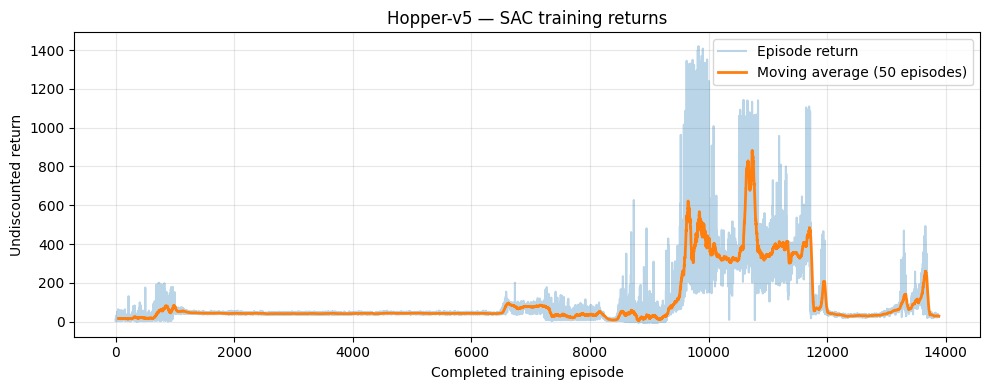

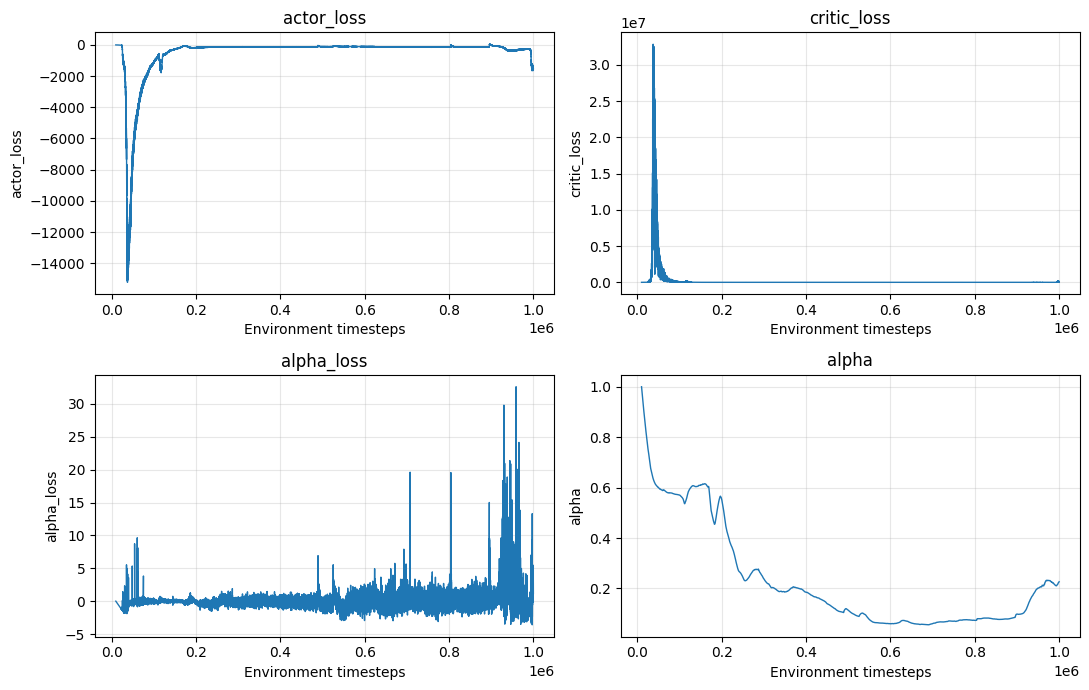

In [19]:
# 7. Visualize episode returns and optimization metrics
returns = np.asarray(agent.completed_returns, dtype=np.float64)
fig, ax = plt.subplots(figsize=(10, 4))
if len(returns):
    ax.plot(returns, alpha=0.3, label="Episode return")
    window = min(50, len(returns))
    smoothed = np.convolve(returns, np.ones(window)/window, mode="valid")
    ax.plot(np.arange(window-1, len(returns)), smoothed,
            linewidth=2, label=f"Moving average ({window} episodes)")
ax.set(xlabel="Completed training episode", ylabel="Undiscounted return",
       title="Hopper-v5 — SAC training returns")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(RUN_DIR / "episode_returns.png", dpi=160)
plt.show()

if history:
    fig, axs = plt.subplots(2, 2, figsize=(11, 7))
    keys = ["actor_loss", "critic_loss", "alpha_loss", "alpha"]
    steps = [row["timesteps"] for row in history]
    for ax, key in zip(axs.flat, keys):
        ax.plot(steps, [row[key] for row in history], linewidth=1)
        ax.set(xlabel="Environment timesteps", ylabel=key, title=key)
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(RUN_DIR / "optimization_metrics.png", dpi=160)
    plt.show()

In [21]:
# 8. Optionally reload the saved policy (for a fresh notebook session)
checkpoint_path = RUN_DIR / "hopper_ldr_best.pt"
if checkpoint_path.exists():
    inference_env = makeVecEnv([make_hopper])
    inference_agent = LDRAgent(inference_env, config=LDRConfig(**config.__dict__))
    inference_agent.load(str(checkpoint_path))
    inference_env.close()
else:
    # Can be useful if training is still underway in this kernel
    inference_agent = agent
print("Inference policy ready")

Inference policy ready


In [ ]:
# Create output directory
VIDEO_DIR = Path("./videos")
VIDEO_DIR.mkdir(exist_ok=True)

# Headless rendering environment
env = gym.make(
    "Hopper-v5",
    render_mode="rgb_array"
)

obs, info = env.reset(seed=42)
frames = []
total_reward = 0.0

fps = round(1.0 / env.unwrapped.dt)

for step in range(1000):

    # Use the trained policy from your notebook
    action = inference_agent.predict(
        obs[None, :],
        deterministic=True
    )[0]

    obs, reward, terminated, truncated, info = (
        env.step(action)
    )

    frame = env.render()
    frames.append(frame)

    total_reward += reward

    if terminated or truncated:
        break

env.close()

# Save MP4
video_path = VIDEO_DIR / "hopper_sac.mp4"

imageio.mimsave(
    str(video_path),
    frames,
    fps=fps,
    macro_block_size=16
)

print(f"Episode reward: {total_reward:.2f}")
print(f"Video saved: {video_path.resolve()}")

# Display inside Jupyter
display(Video(
    filename=str(video_path),
    embed=True
))

Episode reward: 3292.61
Video saved: /network/rit/dgx/dgx_dahlin_lab/Gobinda/Latent-Dynamics-Geometries/simplified/videos/hopper_sac.mp4


In [17]:
import gymnasium as gym

env_fns, anchor_indices = make_anchored_env_fns(
    num_envs=16,
    anchor_fraction=0.25,
    env_fn=lambda: gym.make("Hopper-v5"),
    seed=42,
    multi_episode_dynamics=3,
    mass_range=(0.5, 2.0),
    damping_range=(0.5, 2.0),
    torque_range=(0.5, 2.0),
)

venv = makeVecEnv(env_fns)
env = GlobalDynamicsIDWrapper(venv)

env.seed(42)
obs = env.reset()

print("Anchor indices:", anchor_indices)
print("Initial dynamics IDs:", env.dynamics_ids)
print(env.records)

Anchor indices: [1, 7, 9, 10]
Initial dynamics IDs: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16]
    dynamics_id                                         parameters
0             0  (3.6651914291880923, 4.057890510886818, 2.7813...
1             1  (4.245455958346043, 7.255089783256747, 4.30012...
2             2  (2.073263126111424, 2.1508620612142106, 4.8919...
3             3  (3.251646458721875, 4.498805034474918, 5.43414...
4             4  (4.738127538113487, 6.677158848036426, 4.77708...
5             5  (2.2571721854690896, 3.688032594588873, 3.9850...
6             6  (5.976106448023718, 4.860422793339374, 1.82342...
7             7  (5.1080315486835675, 5.156364789838122, 4.2881...
8             8  (5.093977941024865, 4.414681824247736, 3.99277...
9             9  (6.415932264433076, 5.363949720224605, 5.45194...
10           10  (3.5211770459007017, 3.5805200748715857, 2.319...
11           11  (4.989569660359396, 5.191321695423887, 1.41733...
12           12  (5.7850134

In [ ]:
# For change and nominal
env_fns = [
    lambda: PhysicsWrapper(
        gym.make("Hopper-v5"),
        mode="nominal",
        mass_scale=1.0,
        damping_scale=1.0,
        torque_scale=1.0,
    ),
    lambda: PhysicsWrapper(
        gym.make("Hopper-v5"),
        mode="change",
        mass_scale=1.5,
        damping_scale=1.0,
        torque_scale=1.0,
    ),
    lambda: PhysicsWrapper(
        gym.make("Hopper-v5"),
        mode="change",
        mass_scale=1.5,
        damping_scale=1.0,
        torque_scale=1.0,
    ),
    lambda: PhysicsWrapper(
        gym.make("Hopper-v5"),
        mode="change",
        mass_scale=2.0,
        damping_scale=1.0,
        torque_scale=1.0,
    ),
]

venv = makeVecEnv(env_fns)
env = GlobalDynamicsIDWrapper(venv)

obs = env.reset()

print(env.dynamics_ids)
print(env.records)

In [ ]:
class EmbeddingVisualizer:
    def __init__(self, agent, env_fn, physics_wrapper_cls=None):
        """env_fn is a zero-argument factory returning a NEW single Gymnasium env."""
        self.agent = agent
        self.env_fn = env_fn
        self.physics_wrapper_cls = physics_wrapper_cls

    def rollout(self, seed=2026, max_steps=1000, physics=None):
        """Return encoder means (T, latent_dim) for one deterministic episode.

        physics: optional dict of PhysicsWrapper kwargs, e.g.
            {'mode': 'custom', 'mass_scale': 1.2}
        """
        env = self.env_fn()
        try:
            if physics is not None:
                if self.physics_wrapper_cls is None:
                    raise ValueError('Pass PhysicsWrapper as physics_wrapper_cls to scan physics.')
                env = self.physics_wrapper_cls(env, **physics)

            obs, _ = env.reset(seed=seed)
            H = self.agent.config.n_past
            obs_dim, act_dim = self.agent.obs_dim, self.agent.action_dim
            history = np.zeros((1, H, obs_dim + act_dim), dtype=np.float32)
            latents = []
            self.agent.encoder.eval()
            self.agent.actor.eval()
            for _ in range(max_steps):
                # Encode only *past* observation/action pairs before choosing a_t.
                with torch.no_grad():
                    history_t = torch.as_tensor(history, device=self.agent.device)
                    z = self.agent.encoder(history_t).loc
                    obs_t = torch.as_tensor(obs, dtype=torch.float32,
                                            device=self.agent.device).reshape(1, -1)
                    # Same action scaling as standalone LDRAgent.predict().
                    normalized_action = self.agent.actor.predict(
                        torch.cat((obs_t, z), dim=-1), deterministic=True
                    ).cpu().numpy()[0]
                latents.append(z.cpu().numpy()[0].copy())
                low = np.asarray(env.action_space.low)
                high = np.asarray(env.action_space.high)
                action = low + 0.5 * (high - low) * (normalized_action + 1.0)
                next_obs, _, terminated, truncated, _ = env.step(action)
                history[:, 1:] = history[:, :-1].copy()
                history[0, 0, :obs_dim] = obs
                history[0, 0, obs_dim:] = normalized_action
                obs = next_obs
                if terminated or truncated:
                    break
            return np.asarray(latents, dtype=np.float32)
        finally:
            env.close()

    @staticmethod
    def project(latents, method='pca', seed=42):
        """Project stacked latent vectors to 2D. Uses sklearn for pca/tsne."""
        latents = np.asarray(latents, dtype=np.float32)
        if latents.ndim != 2 or len(latents) < 2:
            raise ValueError('Need at least two latent vectors with shape (N, latent_dim).')
        if latents.shape[1] == 2:
            return latents.copy()
        if latents.shape[1] == 1:
            return np.column_stack((latents[:, 0], np.zeros(len(latents))))
        if method == 'pca':
            from sklearn.decomposition import PCA
            return PCA(n_components=2).fit_transform(latents)
        if method == 'tsne':
            from sklearn.manifold import TSNE
            perplexity = min(30, max(1, (len(latents) - 1) // 3))
            return TSNE(n_components=2, perplexity=perplexity,
                        random_state=seed, init='pca', learning_rate='auto').fit_transform(latents)
        raise ValueError("method must be 'pca' or 'tsne'")

    def plot_trajectories(self, num_trajs=10, samples_per_traj=100,
                          method='pca', seed=2026, max_steps=1000):
        """Color embeddings by rollout/trajectory, matching original separation plot."""
        groups, labels = [], []
        for i in range(num_trajs):
            z = self.rollout(seed=seed + i, max_steps=max_steps)
            if len(z) == 0:
                continue
            indices = np.linspace(0, len(z)-1, min(len(z), samples_per_traj), dtype=int)
            groups.append(z[indices])
            labels.extend([i] * len(indices))
        if not groups:
            raise RuntimeError('No rollout embeddings collected')
        xy = self.project(np.concatenate(groups), method)
        fig, ax = plt.subplots(figsize=(7, 6))
        scatter = ax.scatter(xy[:, 0], xy[:, 1], c=labels, cmap='tab20', s=16, alpha=.8)
        fig.colorbar(scatter, ax=ax, label='Trajectory index')
        ax.set(title=f'LDR latent embeddings by trajectory ({method.upper()})', xlabel='Component 1', ylabel='Component 2')
        fig.tight_layout()
        return fig, ax

    def plot_physics_scan(self, parameter='mass', values=None, train_range=(0.5, 2.0),
                          samples_per_value=20, method='pca', seed=2026, max_steps=1000):
        """Scan one global multiplier while others stay at nominal (1.0).

        parameter: 'mass', 'damping', or 'torque'. Each rollout uses same seed.
        """
        names = {'mass': 'mass_scale', 'damping': 'damping_scale', 'torque': 'torque_scale'}
        if parameter not in names:
            raise ValueError(f'parameter must be one of {list(names)}')
        if values is None:
            values = np.linspace(0.3, 2.5, 15)
        groups, labels = [], []
        for value in values:
            physics = {'mode': 'custom', names[parameter]: float(value)}
            z = self.rollout(seed=seed, max_steps=max_steps, physics=physics)
            if not len(z):
                continue
            idx = np.linspace(0, len(z)-1, min(len(z), samples_per_value), dtype=int)
            groups.append(z[idx])
            labels.extend([float(value)] * len(idx))
        if not groups:
            raise RuntimeError('No rollout embeddings collected')
        xy = self.project(np.concatenate(groups), method)
        labels = np.asarray(labels)
        in_distribution = (labels >= train_range[0]) & (labels < train_range[1])
        fig, ax = plt.subplots(figsize=(7, 6))
        norm = plt.Normalize(vmin=float(np.min(labels)), vmax=float(np.max(labels)))
        for mask, marker, name in [(in_distribution, 'o', 'In distribution'),
                                   (~in_distribution, '^', 'Out of distribution')]:
            if np.any(mask):
                ax.scatter(xy[mask, 0], xy[mask, 1], c=labels[mask],
                           cmap='coolwarm', norm=norm, s=23, marker=marker,
                           alpha=.8, label=name)
        fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap='coolwarm'), ax=ax,
                     label=f'{parameter} multiplier')
        ax.set(title=f'LDR latent scan: {parameter} ({method.upper()})',
               xlabel='Component 1', ylabel='Component 2')
        ax.legend()
        fig.tight_layout()
        return fig, ax
